# TP3 — Classifieurs et méthodes d'ensemble (corrigé)
**CNFSDP — Introduction au Machine Learning** · L3 S5 · 2026-2027 · Rois Céti DIMBAMBA · chapitre 3 · 45 min en salle

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rdimbamba/ml-cnfsdp/blob/main/notebooks/corriges/TP3_corrige.ipynb)

Partie A : plus proches voisins et régression logistique. Partie B : arbres et indice de Gini. Partie C : bagging, forêt, AdaBoost.
Données : le fil rouge du cours (10 enfants, chiffres fictifs), des « croissants » simulés et `breast_cancer`, fourni avec scikit-learn (aucun téléchargement).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
VERT, OR, GRIS = "#126B2A", "#B8860B", "#8A8A8A"   # couleurs du cours

# Fil rouge : études de la mère (ans), distance au centre de santé (km), vacciné
X0 = np.array([[0, 9], [1, 3], [3, 7], [4, 2], [6, 8], [6, 4], [7, 9], [9, 6], [10, 1], [2, 5]])
y0 = np.array([0, 1, 0, 1, 0, 1, 1, 1, 1, 0])

## Partie A — Plus proches voisins et régression logistique
### Question 1 — $k$-NN à la main
Pour le nouvel enfant $x=(5,5)$ : calculer les distances au carré aux 10 enfants, trier, puis donner $\hat\eta(x)$ et la prédiction pour $k=1,3,5$. Vérifier avec `KNeighborsClassifier`.

In [2]:
x = np.array([5, 5])
d2 = ((X0 - x) ** 2).sum(axis=1)                 # distances au carré
ordre = np.argsort(d2, kind="stable")
print("enfants par distance :", ordre + 1, "| d² :", d2[ordre])
for k in [1, 3, 5]:
    eta = y0[ordre[:k]].mean()
    sk = KNeighborsClassifier(n_neighbors=k).fit(X0, y0).predict_proba([x])[0, 1]
    print(f"k = {k} : eta = {eta:.3f} -> prédiction {int(eta > 0.5)} | scikit-learn : {sk:.3f}")

enfants par distance : [ 6  3 10  4  5  8  2  7  1  9] | d² : [ 2  8  9 10 10 17 20 20 41 41]
k = 1 : eta = 1.000 -> prédiction 1 | scikit-learn : 1.000
k = 3 : eta = 0.333 -> prédiction 0 | scikit-learn : 0.333
k = 5 : eta = 0.400 -> prédiction 0 | scikit-learn : 0.400


### Question 2 — Choisir $k$ par validation croisée
Sur 300 points en croissants (`make_moons(noise=0.3)`), calculer l'erreur de validation croisée à 5 blocs pour $k=1,\dots,50$, tracer la courbe et donner le meilleur $k$. Mesurer ensuite l'erreur test sur 5 000 nouveaux points.

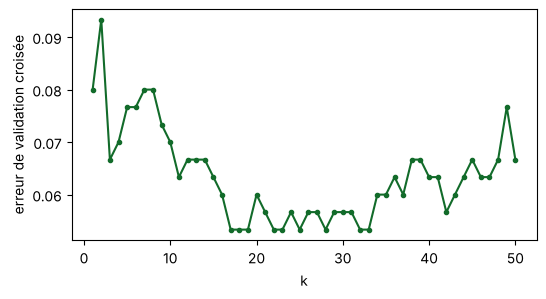

k choisi : 17 | erreur test : 0.0918


In [3]:
X, y = make_moons(n_samples=300, noise=0.3, random_state=0)
Xt, yt = make_moons(n_samples=5000, noise=0.3, random_state=1)
ks = range(1, 51)
err = [1 - cross_val_score(KNeighborsClassifier(n_neighbors=k), X, y, cv=5).mean() for k in ks]
k_opt = ks[int(np.argmin(err))]
plt.figure(figsize=(6, 3)); plt.plot(ks, err, color=VERT, marker="o", ms=3)
plt.xlabel("k"); plt.ylabel("erreur de validation croisée"); plt.show()
f = KNeighborsClassifier(n_neighbors=k_opt).fit(X, y)
print("k choisi :", k_opt, "| erreur test :", round(np.mean(f.predict(Xt) != yt), 4))

### Question 3 — Régression logistique sur le fil rouge
Avec la seule variable « études », ajuster une régression logistique sans pénalité (`LogisticRegression(C=1e8)`). Retrouver $\hat\theta\approx(-1{,}46;\,0{,}43)$, la frontière $-\hat\theta_0/\hat\theta_1$, la cote $e^{\hat\theta_1}$ et la perte logistique moyenne. Vérifier que le gradient $\frac1n\sum_i(\hat\eta_i-y_i)x_{ij}$ est (presque) nul.

In [4]:
xe = X0[:, [0]]                                  # années d'études seules
lr = LogisticRegression(C=1e8).fit(xe, y0)
t0, t1 = lr.intercept_[0], lr.coef_[0, 0]
eta = lr.predict_proba(xe)[:, 1]
perte = -np.mean(y0 * np.log(eta) + (1 - y0) * np.log(1 - eta))
print(f"theta = ({t0:.2f} ; {t1:.2f}) | frontière : {-t0 / t1:.2f} ans | cote : {np.exp(t1):.2f}")
print(f"perte logistique moyenne : {perte:.3f} (constante 0,6 : {-np.mean(y0*np.log(.6)+(1-y0)*np.log(.4)):.3f})")
print("gradient :", np.mean(eta - y0).round(5), np.mean((eta - y0) * xe[:, 0]).round(5))

theta = (-1.46 ; 0.43) | frontière : 3.42 ans | cote : 1.53
perte logistique moyenne : 0.518 (constante 0,6 : 0.673)
gradient : -1e-05 3e-05


## Partie B — Arbres et indice de Gini
### Question 4 — La meilleure coupure
Écrire une fonction `gini(y)` qui renvoie $2p(1-p)$, puis une fonction qui calcule l'impureté moyenne d'une coupure « $x_j\le s$ ». Essayer tous les seuils (milieux entre valeurs consécutives) des deux variables du fil rouge et retrouver la coupure du cours (distance $\le4{,}5$, impureté $0{,}267$). Comparer avec l'arbre de profondeur 2 de scikit-learn.

In [5]:
def gini(y):
    p = y.mean()
    return 2 * p * (1 - p)

def impurete(X, y, j, s):
    g = X[:, j] <= s
    return g.mean() * gini(y[g]) + (1 - g.mean()) * gini(y[~g])

resultats = []
for j, nom in enumerate(["études", "distance"]):
    v = np.unique(X0[:, j])
    for s in (v[:-1] + v[1:]) / 2:
        resultats.append((impurete(X0, y0, j, s), nom, s))
for r in sorted(resultats)[:4]:
    print(f"{r[1]:8s} <= {r[2]:4.1f} : impureté {r[0]:.3f}")

arbre = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X0, y0)
print(export_text(arbre, feature_names=["études", "distance"]))

distance <=  4.5 : impureté 0.267
distance <=  6.5 : impureté 0.317
études   <=  3.5 : impureté 0.317
distance <=  3.5 : impureté 0.343
|--- distance <= 4.50
|   |--- class: 1
|--- distance >  4.50
|   |--- études <= 6.50
|   |   |--- class: 0
|   |--- études >  6.50
|   |   |--- class: 1



## Partie C — Méthodes d'ensemble sur `breast_cancer`
569 tumeurs, 30 mesures ; $y=1$ si la tumeur est bénigne. Découpage 70 % / 30 %, stratifié.

In [6]:
D = load_breast_cancer()
Xa, Xt, ya, yt = train_test_split(D.data, D.target, test_size=0.3, random_state=0, stratify=D.target)
print(Xa.shape, Xt.shape)

(398, 30) (171, 30)


### Question 5 — Le bagging écrit en NumPy
Pour $B=100$ : tirer un échantillon bootstrap (indices avec remise), y apprendre un arbre profond, prédire le test ; agréger par vote majoritaire. Comparer l'exactitude test avec un arbre seul et avec `BaggingClassifier`. Tracer l'exactitude du vote en fonction du nombre d'arbres.

arbre seul 0.906 | bagging NumPy 0.918 | BaggingClassifier 0.936


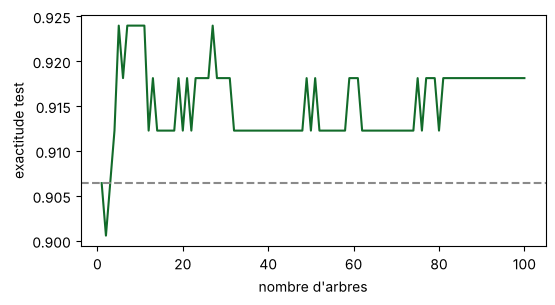

In [7]:
rng = np.random.default_rng(0)
B, n = 100, len(ya)
votes = np.zeros(len(yt))
exactitude = []
for b in range(1, B + 1):
    idx = rng.integers(0, n, n)                          # échantillon bootstrap
    arbre_b = DecisionTreeClassifier(random_state=b).fit(Xa[idx], ya[idx])
    votes += arbre_b.predict(Xt)
    exactitude.append(np.mean((votes / b > 0.5) == yt))  # vote majoritaire des b premiers arbres

seul = DecisionTreeClassifier(random_state=0).fit(Xa, ya).score(Xt, yt)
sk = BaggingClassifier(DecisionTreeClassifier(), n_estimators=B, random_state=0).fit(Xa, ya).score(Xt, yt)
print(f"arbre seul {seul:.3f} | bagging NumPy {exactitude[-1]:.3f} | BaggingClassifier {sk:.3f}")
plt.figure(figsize=(6, 3)); plt.plot(range(1, B + 1), exactitude, color=VERT)
plt.axhline(seul, color=GRIS, ls="--"); plt.xlabel("nombre d'arbres"); plt.ylabel("exactitude test"); plt.show()

### Question 6 — Forêt aléatoire : out-of-bag et importances
Ajuster `RandomForestClassifier(n_estimators=300, oob_score=True)`. Comparer l'exactitude out-of-bag à l'exactitude test, puis afficher les cinq variables les plus importantes.

In [8]:
foret = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=0).fit(Xa, ya)
print("OOB :", round(foret.oob_score_, 3), "| test :", round(foret.score(Xt, yt), 3))
ordre = np.argsort(foret.feature_importances_)[::-1][:5]
for j in ordre:
    print(f"{D.feature_names[j]:25s} {foret.feature_importances_[j]:.3f}")

OOB : 0.967 | test : 0.953
worst perimeter           0.134
worst radius              0.132
worst concave points      0.117
mean concave points       0.108
worst area                0.107


### Question 7 — AdaBoost à la main
Six points $x=1,\dots,6$, classes $y=(+1,+1,-1,+1,+1,-1)$. Programmer trois tours d'AdaBoost avec des arbres à une coupure (`DecisionTreeClassifier(max_depth=1)` accepte des poids : `fit(x, y, sample_weight=w)`). À chaque tour, afficher la coupure, $\varepsilon_m$, $\alpha_m$ et les nouveaux poids ; vérifier que les mal classés pèsent $\frac12$ après la mise à jour. Comparer avec `AdaBoostClassifier`, dont les poids valent $2\alpha_m$.

In [9]:
x6 = np.arange(1, 7).reshape(-1, 1); y6 = np.array([1, 1, -1, 1, 1, -1])
w = np.full(6, 1 / 6); F = np.zeros(6)
for m in range(1, 4):
    h = DecisionTreeClassifier(max_depth=1).fit(x6, y6, sample_weight=w)
    pred = h.predict(x6)
    eps = w[pred != y6].sum()
    alpha = 0.5 * np.log((1 - eps) / eps)
    w = w * np.exp(-alpha * y6 * pred); w = w / w.sum()
    F += alpha * pred
    print(f"tour {m} : coupure {h.tree_.threshold[0]}, eps = {eps:.4f}, alpha = {alpha:.3f}, "
          f"poids = {w.round(4)}, mal classés : {w[pred != y6].sum():.2f}")
print("F =", F.round(2), "| prédiction :", np.sign(F).astype(int), "| erreurs :", int(np.sum(np.sign(F) != y6)))

ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=3, random_state=0).fit(x6, y6)
print("scikit-learn : poids", ada.estimator_weights_.round(3), "= 2 alpha ; prédiction", ada.predict(x6))

tour 1 : coupure 5.5, eps = 0.1667, alpha = 0.805, poids = [0.1 0.1 0.5 0.1 0.1 0.1], mal classés : 0.50
tour 2 : coupure 2.5, eps = 0.2000, alpha = 0.693, poids = [0.0625 0.0625 0.3125 0.25   0.25   0.0625], mal classés : 0.50
tour 3 : coupure 3.5, eps = 0.1875, alpha = 0.733, poids = [0.1667 0.1667 0.1923 0.1538 0.1538 0.1667], mal classés : 0.50
F = [ 0.76  0.76 -0.62  0.84  0.84 -0.76] | prédiction : [ 1  1 -1  1  1 -1] | erreurs : 0
scikit-learn : poids [1.609 1.386 1.466] = 2 alpha ; prédiction [ 1  1 -1  1  1 -1]


**Conclusion attendue.** Chaque coupure seule fait au moins une erreur, mais le vote pondéré des trois classe les six points sans erreur. Sur `breast_cancer`, le bagging et la forêt font nettement mieux qu'un arbre seul ; l'erreur out-of-bag donne une bonne idée de l'erreur test sans données mises de côté.